# 15 · When the profile is not enough

**Level:** advanced · **Prerequisites:** [14](14_profile_importance_sampling.ipynb) · **Run time:** ~1 min

**Covers:** when `MarginalTransitModel.profile_is` does not accept the profile proposal (k̂ ≥ 0.5, ESS < 25% of the draws, or an incomplete profile); the bounded retry in unbounded coordinates (β = b/(1 + Rp/R★) for grazing geometries); the flat-limb-darkening proposal; the adaptive rescue; reading `FitResult.diagnostics`

The profile proposal of notebook 14 assumes that, at each b, the other parameters are close to Gaussian. Three
kinds of light curves break that assumption: grazing transits, where the conditional posterior of Rp/R★ becomes a
long, curved ridge; posteriors that pile up against a prior bound; and transits barely above the noise, where the
posterior spreads over most of the prior. `fit()` handles all of them without user input, in this order:

1. **Profile proposal** (notebook 14). It is accepted only if the profile closed within its grid, k̂ < 0.5 and the
   ESS is at least 25% of the draws.
2. **Bounded retry**: the same construction in unbounded coordinates (logit/log of the bounded parameters; for a
   posterior that reaches grazing geometries, β = b/(1 + Rp/R★), which stays below 1 on the whole grazing branch).
3. **Flat-limb-darkening proposal**: the proposal is built on the posterior with a flat prior over the
   limb-darkening coefficients, which is smooth, and the draws are weighted against the physical posterior.
4. **Adaptive rescue**: the weighted draws of all attempts are pooled and refined by adaptive multiple
   importance sampling (notebook 12, section 5), with a component over the whole prior box, until k̂ < 0.7, the ESS
   reaches 25% of the draws and the quantiles no longer move.

`result.diagnostics` says which of them ran. This notebook shows each on a simulated light curve.

In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pizzetti

SMOKE = os.environ.get("PIZZETTI_SMOKE") == "1"
warnings.filterwarnings("ignore", category=RuntimeWarning)

def simulate(rp, a, b, per, sigma, n_transits, cadence, half_window, exptime=0.0, k=1, seed=3,
             u=(0.40, 0.25)):
    # folded light curve: windows of +-half_window days around n_transits transits
    t = (np.arange(n_transits)[:, None] * per + np.arange(-half_window, half_window, cadence)[None, :]).ravel()
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = 0.0, per, rp, a
    p.inc = np.degrees(np.arccos(b / a))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", list(u)
    kw = dict(supersample_factor=k, exp_time=exptime, offsets="midpoint") if k > 1 else {}
    y = pizzetti.TransitModel(p, t, **kw).light_curve(p) + sigma * np.random.default_rng(seed).standard_normal(t.size)
    return p, t, y, kw

def report(r, label):
    print(f"{label}: k-hat {r['khat']:.2f}, ESS {r['ess']:.0f}, profile complete {r['complete']}, "
          f"bounded retry {r['bounded_retry']}, flat proposal {r['flat_proposal']}, rescue {r['rescue']}, "
          f"usable {r['is_ok']}")

## 1. A grazing branch

An ultra-short-period super-Earth like K2-131 b: Rp/R★ = 0.017, P = 0.37 d, b = 0.4, 147 transits at K2's
30-min cadence (15 sub-exposures) with 415 ppm noise. At this signal-to-noise ratio the data also allow a grazing
geometry, b > 1 with a much larger planet, a long branch reaching to the prior bound Rp/R★ = 0.5.

We call `model.profile_is` directly: once with the rescue switched off (`rescue=False`), to see what the profile
and its retries give on their own, and once with the defaults, as `fit()` runs it.

In [2]:
exp = 1765.5 / 86400
p, t, y, kw = simulate(rp=0.0172, a=3.0, b=0.4, per=0.369, sigma=415e-6, n_transits=147, cadence=exp,
                       half_window=0.0625, exptime=exp, k=15)
model = pizzetti.MarginalTransitModel(p, t, y, 415e-6, bounds={"rp": (1e-4, 0.5), "t0": (-0.02, 0.02)}, **kw)
jb, jr = model.free.index("b"), model.free.index("rp")
print(len(t), "points, free:", model.free)

t_start = time.perf_counter()
r_off = model.profile_is(n=4000, rng=np.random.default_rng(1), rescue=False)
report(r_off, f"without the rescue ({time.perf_counter() - t_start:.0f} s)")
t_start = time.perf_counter()
r_on = model.profile_is(n=4000, rng=np.random.default_rng(1))
report(r_on, f"with the rescue    ({time.perf_counter() - t_start:.0f} s)")
for h in r_on["pmc"]:
    print(f"   rescue iteration: k-hat {h['khat']:.2f}, ESS {h['ess']:.0f} of {h['n']}, quantile change {h['dq']:.3f} sd")

def weighted(r):
    X = model.to_physical(r["theta"])
    return X, r["w"] / r["w"].sum()

for r, label in ((r_off, "without the rescue"), (r_on, "with the rescue")):
    X, w = weighted(r)
    print(f"P(b > 1), the grazing branch, {label}: {np.sum(w[X[:, jb] > 1]):.3f}")

1029 points, free: ['t0', 'per', 'rp', 'a', 'b']


without the rescue (20 s): k-hat 0.38, ESS 1860, profile complete False, bounded retry True, flat proposal False, rescue None, usable False


with the rescue    (23 s): k-hat 0.45, ESS 2442, profile complete False, bounded retry True, flat proposal False, rescue True, usable True
   rescue iteration: k-hat 0.66, ESS 53 of 4000, quantile change inf sd
   rescue iteration: k-hat 0.52, ESS 117 of 8000, quantile change 0.475 sd
   rescue iteration: k-hat 0.62, ESS 258 of 12000, quantile change 0.487 sd
   rescue iteration: k-hat 0.55, ESS 696 of 16000, quantile change 0.398 sd
   rescue iteration: k-hat 0.53, ESS 1158 of 20000, quantile change 0.306 sd
   rescue iteration: k-hat 0.59, ESS 1004 of 24000, quantile change 0.170 sd
   rescue iteration: k-hat 0.46, ESS 2307 of 28000, quantile change 0.109 sd
   rescue iteration: k-hat 0.45, ESS 2442 of 32000, quantile change 0.070 sd
P(b > 1), the grazing branch, without the rescue: 0.267
P(b > 1), the grazing branch, with the rescue: 0.260


The profile cannot close: along b the conditional posterior turns into the grazing ridge, the conditional fits
stop being Gaussian, and the grid ends early (`complete` False), also in the bounded retry. Without the rescue, the
best attempt has a perfectly good k̂ and ESS, and yet it is not usable: an incomplete profile may have stopped
short of part of the posterior, which is exactly the blind spot of notebook 12 (weights cannot report what the
proposal never reached). Here it under-weights the grazing branch. The rescue starts from all attempts' draws, adds
a component over the whole prior box, and iterates until k̂, the ESS and the quantiles are stable.

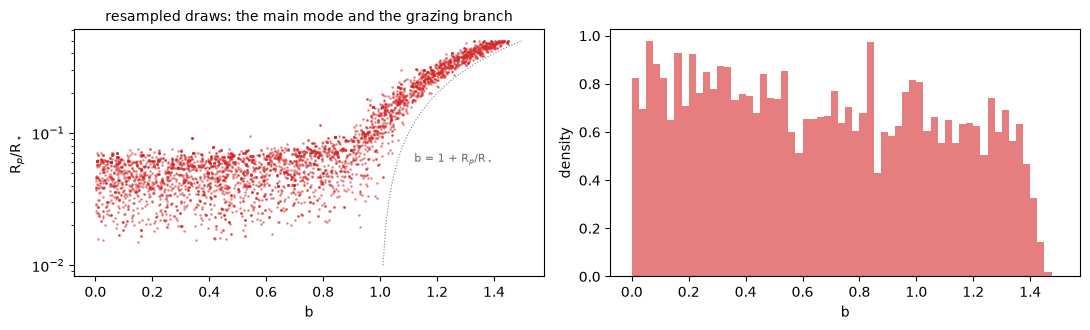

In [3]:
X1, w1 = weighted(r_on)
sel = np.random.default_rng(0).choice(len(X1), 4000, p=w1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(X1[sel, jb], X1[sel, jr], ".", ms=2, color="C3", alpha=0.4)
bb = np.linspace(1.01, 1.5, 50)
ax[0].plot(bb, bb - 1.0, color="0.5", ls=":", lw=0.8)          # b = 1 + Rp/R*: the planet just touches the limb
ax[0].text(1.12, 0.06, "b = 1 + R$_p$/R$_\\star$", color="0.4", fontsize=8)
ax[0].set_xlabel("b"); ax[0].set_ylabel("R$_p$/R$_\\star$"); ax[0].set_yscale("log")
ax[0].set_title("resampled draws: the main mode and the grazing branch", fontsize=10)
ax[1].hist(X1[:, jb], bins=60, range=(0, 1.5), weights=w1, density=True, histtype="stepfilled", color="C3", alpha=0.6)
ax[1].set_xlabel("b"); ax[1].set_ylabel("density")
fig.tight_layout()

## 2. Why the acceptance thresholds are k̂ < 0.5 and an ESS of 25%

PSIS estimates are usable up to k̂ ≈ 0.7 (notebook 12), and earlier versions of pizzetti accepted the profile
proposal up to there, with an ESS of only 10% of the draws. Two light curves of the paper's extended tests showed
why that is not enough:

- **K2-131 b** (the real light curve behind case 1, with a lighter grazing branch holding 7% of the posterior): two
  of three runs were accepted after the bounded retry, at k̂ = 0.69 and 0.65, without a single draw on the
  branch, and the 97.5% quantile of Rp/R★ came out 3.8 posterior standard deviations too low. Between 0.5 and 0.7
  the weights have a finite mean but infinite variance; here that was the visible sign of a proposal that
  barely touched part of the posterior. With k̂ < 0.5 required, all three runs went on to the rescue and found
  the branch (6–7% of the mass, against 6–8% in two emcee chains).
- **Kepler-21 b**: a run with k̂ = 0.43 but an ESS of 900 of 4000 draws was 0.37 standard deviations off in the 2.5%
  quantile of T₁₄; the tails carried the noise of a few hundred effective draws. With 40 000 draws the same run was
  within 0.06.

The thresholds are `profile_is(khat_ok=0.5, ess_min=0.25)`. They cost a rescue for a few per cent of light curves,
which `fit()` runs automatically.

## 3. A transit barely above the noise

A planet with Rp/R★ = 0.03 in 1000 ppm noise, six transits at 30-min cadence: a transit signal-to-noise ratio of
about 5. The posterior spreads over most of the prior (Rp/R★ up to its bound, a/R★ over its whole box), which no
profile around a single maximum describes.

In [4]:
exp = 1765.5 / 86400
p, t, y, kw = simulate(rp=0.03, a=10.0, b=0.5, per=3.0, sigma=1e-3, n_transits=6, cadence=exp,
                       half_window=0.25, exptime=exp, k=15, seed=1)
model = pizzetti.MarginalTransitModel(p, t, y, 1e-3, free=("t0", "rp", "a", "b"),
                                      bounds={"t0": (-0.03, 0.03), "rp": (0.0, 0.5), "a": (2.0, 40.0)}, **kw)
t_start = time.perf_counter()
result = model.fit(seed=0, n=4000)
print(f"fit(): {time.perf_counter() - t_start:.0f} s")
d = result.diagnostics
print(f"method {d['method']}, k-hat {d['khat']:.2f}, ESS {d['ess']:.0f}, complete {d['complete']}, "
      f"bounded_retry {d['bounded_retry']}, flat_proposal {d['flat_proposal']}, rescue {d['rescue']} "
      f"({d['rescue_iters']} iterations), is_ok {d['is_ok']}")
rp = result.samples[:, result.labels.index("rp")]
a = result.samples[:, result.labels.index("a")]
print(f"Rp/R*: median {np.median(rp):.3f}, 97.5% quantile {np.percentile(rp, 97.5):.3f}  (truth 0.03)")
print(f"a/R*:  2.5-97.5% {np.percentile(a, 2.5):.1f} - {np.percentile(a, 97.5):.1f}  (truth 10, prior 2-40)")

fit(): 7 s
method profile-IS, k-hat 0.40, ESS 5338, complete False, bounded_retry True, flat_proposal False, rescue True (3 iterations), is_ok True
Rp/R*: median 0.040, 97.5% quantile 0.456  (truth 0.03)
a/R*:  2.5-97.5% 2.9 - 36.9  (truth 10, prior 2-40)


## Reading `diagnostics`

| key | meaning |
|---|---|
| `method` | `profile-IS` (always, when b is free; `emcee` only for `method="emcee"`) |
| `khat`, `ess` | of the returned draws |
| `complete` | whether the profile closed within its grid (12 nats down or a wall) |
| `bounded_retry`, `flat_proposal` | `None`: not run; `False`: run, not used; `True`: its draws are the result (or seeded the rescue) |
| `rescue`, `rescue_iters` | whether the adaptive rescue ran, and its iterations |
| `is_ok` | whether the returned draws pass the diagnostics |

If `is_ok` is False, `fit()` still returns the draws, with a warning. That did not happen in any of the 300
importance-sampling runs of the paper's extended tests; if it does, compare with `fit(method="emcee")`.

## What you learned

- `fit()` accepts the profile proposal only for a closed profile, k̂ < 0.5 and an ESS of at least 25% of the draws.
- Otherwise it tries the bounded retry (β for grazing posteriors) and the flat-limb-darkening proposal, and
  finishes with adaptive importance sampling from all draws, with a component over the whole prior box.
- Grazing branches, posteriors against a bound and barely detected transits all end in usable importance draws;
  `diagnostics` records the path.

**Next:** [15 · Trusting the result: IS against MCMC](16_is_against_mcmc.ipynb)